# EDA: `raw_lounge_reviews`

One notebook per raw Skytrax table (index in `eda.ipynb`). 

**Role of this table:** Fact table of lounge reviews, one row per review. Joins to `raw_airlines` on `airline_id`.

**Read-only:** the CSV in `data/` is only read. Cleaning below happens on an in-memory copy (`df`); the real cleaning rules are written later in dbt staging.

## Table of Contents

- [0. Setup](#sec-0)
  - [0.1 Imports](#sec-0-1)
  - [0.2 Config](#sec-0-2)
  - [0.3 Plot style](#sec-0-3)
  - [0.4 Helpers](#sec-0-4)
- [1. Look at the Big Picture](#sec-1)
  - [1.1 Frame the Problem](#sec-1-1)
  - [1.2 Questions & Hypotheses](#sec-1-2)
  - [1.3 Performance Measure (for later modelling)](#sec-1-3)
  - [1.4 Check the Assumptions](#sec-1-4)
- [2. Get the Data](#sec-2)
  - [2.1 Data Dictionary](#sec-2-1)
- [3. Data Cleaning (General)](#sec-3)
  - [3.1 Format Column Names](#sec-3-1)
  - [3.2 Format Data Body](#sec-3-2)
  - [3.3 Format Datatypes](#sec-3-3)
  - [3.4 Duplicates](#sec-3-4)
  - [3.5 Domain Sanity Checks](#sec-3-5)
- [4. Data Quality](#sec-4)
  - [4.1 Missing Values](#sec-4-1)
  - [4.2 Outliers](#sec-4-2)
- [5. Attribute Combination](#sec-5)
- [6. EDA](#sec-6)
  - [6.0 Classify Attributes](#sec-6-0)
  - [6.1 Univariate](#sec-6-1)
  - [6.2 Bivariate](#sec-6-2)
  - [6.3 Multivariate](#sec-6-3)
- [7. Summary of Findings](#sec-7)
- [8. Hand-off to Modelling](#sec-8)

# 0. Setup<a id="sec-0"></a>

## 0.1 Imports<a id="sec-0-1"></a>

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

## 0.2 Config<a id="sec-0-2"></a>

Everything dataset-specific lives here. Column names are the **snake_case** names produced in section 3.1.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

TABLE = "lounge_reviews"            # name of the file in data/
DATA_PATH = ROOT / "data" / f"{TABLE}.csv"
TARGET = "recommended"        # yes/no: the business question is what goes with a recommendation
PROBLEM_TYPE = "classification"   # nothing is predicted: this only switches on the target views of the template
ID_COLS = ['review_id']       # identifiers: excluded from analysis
CAT_COLS = ['airline_id']     # force these to categorical; None = auto-detect
CAT_MAX_UNIQUE = 15           # numeric columns with <= this many values are treated as discrete
HIGH_CORR = 0.8               # |r| above this is flagged as multicollinearity
TOP_N_CATEGORIES = 10         # categories shown per bar chart

SAVE_FIGS = False             # True writes every figure to FIG_DIR
FIG_DIR = ROOT / "reports" / "figures"
RANDOM_STATE = 42

## 0.3 Plot style<a id="sec-0-3"></a>

One consistent look: blue for single-series charts, a fixed categorical order for
hue splits (max 3 groups per chart), and a blue ↔ gray ↔ red diverging map for correlations.

In [3]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MAIN = PALETTE[0]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#86b6ef", "#f0efec", "#f19a99", "#b52f2e"])

sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    rc={
        "axes.edgecolor": "#c3c2b7",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#52514e",
        "grid.color": "#ecebe7",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "lines.linewidth": 2,
        "figure.dpi": 100,
    },
)

## 0.4 Helpers<a id="sec-0-4"></a>

In [4]:
def to_snake_case(df):
    """CamelCase / spaces / dashes -> snake_case column names."""
    df = df.copy()
    df.columns = (
        df.columns.str.strip()
        .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)
        .str.replace(r"[\s\-/]+", "_", regex=True)
        .str.lower()
    )
    return df


def save_fig(fig, name):
    if SAVE_FIGS and name:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")


def plot_grid(columns, plot_fn, ncols=4, height=3.0, title=None, name=None, shared_legend=False):
    """Draw plot_fn(col, ax) for every column in a grid of subplots.

    shared_legend=True replaces per-panel legends with one legend above the grid.
    """
    columns = list(columns)
    if not columns:
        print("Nothing to plot.")
        return
    nrows = math.ceil(len(columns) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, height * nrows), squeeze=False)
    axes = axes.ravel()
    for ax, col in zip(axes, columns):
        plot_fn(col, ax)
        ax.set_title(col)
    for ax in axes[len(columns):]:
        ax.axis("off")
    fig.tight_layout()
    legend = axes[0].get_legend()
    if shared_legend and legend:
        handles, labels = legend.legend_handles, [t.get_text() for t in legend.get_texts()]
        fig.legend(handles, labels, title=legend.get_title().get_text(), loc="lower center",
                   bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False)
        for ax in axes:
            if ax.get_legend():
                ax.get_legend().remove()
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=1.0 + (0.7 / fig.get_figheight() if shared_legend and legend else 0))
    save_fig(fig, name)
    plt.show()


def missing_report(df):
    """Count and % of nulls per column (only columns with nulls)."""
    report = pd.DataFrame({
        "n_missing": df.isna().sum(),
        "pct_missing": df.isna().mean() * 100,
        "dtype": df.dtypes.astype(str),
    })
    return report[report.n_missing > 0].sort_values("n_missing", ascending=False)


def outlier_report(df, columns, k=1.5):
    """IQR-based outlier counts. Detection only - nothing is removed."""
    rows = []
    for col in columns:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({"column": col, "lower": lo, "upper": hi, "min": s.min(), "max": s.max(),
                     "n_outliers": n_out, "pct_outliers": 100 * n_out / len(s)})
    return pd.DataFrame(rows).set_index("column").sort_values("n_outliers", ascending=False)


def classify_columns(df, target=None, id_cols=(), cat_cols=None, cat_max_unique=15):
    """Split columns into constant / binary / categorical / discrete / continuous."""
    groups = {"constant": [], "binary": [], "categorical": [], "discrete": [], "continuous": []}
    forced_cat = set(cat_cols or [])
    for col in df.columns:
        if col in id_cols or col == target:
            continue
        n = df[col].nunique(dropna=True)
        if n <= 1:
            groups["constant"].append(col)
        elif n == 2:
            groups["binary"].append(col)
        elif col in forced_cat or not pd.api.types.is_numeric_dtype(df[col]):
            groups["categorical"].append(col)
        elif n <= cat_max_unique:
            groups["discrete"].append(col)
        else:
            groups["continuous"].append(col)
    return groups

# 1. Look at the Big Picture<a id="sec-1"></a>

## 1.1 Frame the Problem<a id="sec-1-1"></a>

Answered before touching the data. Business context: the stakeholder is the Head of Customer Experience of a mid-size full-service airline, who decides how to split the yearly budget for improving the customer experience.

* **What is the business objective?**
  Decide whether and where to upgrade lounges for business and first class guests.
* **How will the output be used?**
  The Head of Customer Experience uses it to see which lounge aspect (comfort, cleanliness, catering, bar, washrooms, wifi, staff) is weakest.
* **What does the target look like?** (regression / classification / none)
  `recommended` (yes/no), so a classification-style view. Nothing is predicted: we only look at which aspects go together with a customer recommending the airline.
* **What would a useful result be?**
  A ranked list of lounge aspects by how strongly they go with `recommended`, with the weakest aspects for business guests.

Main question (all review tables): *which service aspect goes together most with customers recommending the airline, and where is the airline weaker than its peers?*

## 1.2 Questions & Hypotheses<a id="sec-1-2"></a>

The questions this EDA must answer. Each one maps to a section below. Q-numbers follow the business question list; `D1` is the data-readiness check that comes first.

| # | Question | Answered in |
|---|---|---|
| D1 | Can we trust the data enough to answer (lounge names, missing values, duplicates)? | 3, 4 |
| Q1 | For business guests, which lounge aspect scores lowest? | 6.1, 6.3.1 |
| Q2 | Which lounge aspect goes together most with `recommended`? | 6.2 |
| Q3 | How many airlines have at least 100 lounge reviews (enough to be a peer)? | 6.3.1 |
| Q4 | Are some ratings redundant? | 6.3 |

## 1.3 Performance Measure (for later modelling)<a id="sec-1-3"></a>

Pick now so the EDA looks at the right things (e.g. skewed target → consider RMSLE / log target).

* **Regression:** RMSE, MAE, MAPE, RMSLE, adjusted R²
* **Classification:** ROC-AUC, PR-AUC, F1, precision/recall, confusion matrix (check class balance in 6.1)

*Here there is no model, so the "performance measure" is a business one: the recommend rate and the mean-score gap per aspect (built later in the marts).*

## 1.4 Check the Assumptions<a id="sec-1-4"></a>

To confirm with the data owner / stakeholder.

* `review_id` is the primary key; one row = one lounge review.
* `date_visit` is the first day of the visit month, not the exact day.
* `lounge_name` is free text typed by reviewers, so the same lounge can be written in several ways.
* Most lounge reviews come from business class guests, so first class is thin.
* `lounge_name` is missing in about half of the rows, so lounge-level comparisons are limited.
* Reviews are voluntary opinions posted on Skytrax, not a random survey: results describe people who write reviews.
* `recommended` measures how appealing an airline is, not whether the ticket was bought. We say "goes with", never "causes".
* Scores differ strongly by region and nationality, so only compare like with like (same cabin, same region).

# 2. Get the Data<a id="sec-2"></a>

In [5]:
raw = pd.read_csv(DATA_PATH)   # the CSV is only read, never changed
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

5,087 rows x 21 columns


In [6]:
# Take a look at the top 5 rows
raw.head()

,review_id,airline_id,lounge_name,airport,type_of_lounge,type_of_traveller,verify,date_submitted,date_visit,customer_name,nationality,comfort,cleanliness,bar_and_beverages,catering,washrooms,wifi_connectivity,staff_service,recommended,review,updated_at
0,1,9,JFK Terminal 7,New York JFK Airport,Business Class,Business,True,2024-05-21,2024-05-01,Linda Roberts 16,United Kingdom,5.00,5.00,4.00,4.00,4.00,5.00,4.00,True,This is a new lounge for Aer Lingus as on previous occasions they would use ...,2026-06-20 12:45:41
1,2,9,Aer Lingus,New York JFK Airport,Business Class,Business,True,2023-06-15,2023-06-01,Linda Roberts 16,United Kingdom,5.00,5.00,4.00,2.00,5.00,5.00,5.00,True,"A small, clean lounge with plenty of seating, a well-stocked, self-serve bar...",2026-06-20 12:45:41
2,3,9,NaN,London Heathrow Airport,Business Class,Business,False,2023-05-25,2023-05-01,Ronald Lopez 9,Ireland,3.00,3.00,1.00,1.00,3.00,4.00,2.00,False,"While the decor etc is nice, the food is absolutely awful. Soup, cheese and ...",2026-06-20 12:45:41
3,4,9,Dublin,Dublin Airport,Business Class,Business,True,2020-02-04,2020-01-01,Hassan Nelson 16,Canada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,"I would probably rate the lounge as awesome, but since I couldn’t get in I g...",2026-06-20 12:45:41
4,5,9,Gold Circle,Dublin Airport,Frequent Flyer,NaN,False,2017-02-15,2017-02-01,Michelle Thompson 23,Ireland,5.00,5.00,5.00,5.00,5.00,5.00,5.00,True,The Gold Circle Lounge in Dublin T2 is a two storey area with large windows ...,2026-06-20 12:45:41


In [7]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5087 entries, 0 to 5086
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          5087 non-null   int64  
 1   airline_id         5087 non-null   int64  
 2   lounge_name        2676 non-null   str    
 3   airport            4988 non-null   str    
 4   type_of_lounge     4783 non-null   str    
 5   type_of_traveller  3634 non-null   str    
 6   verify             5087 non-null   bool   
 7   date_submitted     5087 non-null   str    
 8   date_visit         2797 non-null   str    
 9   customer_name      5086 non-null   str    
 10  nationality        5086 non-null   str    
 11  comfort            5063 non-null   float64
 12  cleanliness        5059 non-null   float64
 13  bar_and_beverages  4935 non-null   float64
 14  catering           4999 non-null   float64
 15  washrooms          4461 non-null   float64
 16  wifi_connectivity  4644 non-null   

In [8]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,"5,087.00",NaN,NaN,NaN,"2,544.00","1,468.63",1.00,"1,272.50","2,544.00","3,815.50","5,087.00"
airline_id,"5,087.00",NaN,NaN,NaN,297.44,164.80,2.00,151.00,305.00,419.00,595.00
lounge_name,2676,1089,Admirals Club,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airport,4988,320,London Heathrow Airport,410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_of_lounge,4783,5,Business Class,3634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_of_traveller,3634,1,Business,3634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verify,5087,2,False,3986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_submitted,5087,1736,2013-07-07,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_visit,2797,137,2015-08-01,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,5086,3122,Aisha Costa 25,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.1 Data Dictionary<a id="sec-2-1"></a>

One row per column: what it means, its type, how many distinct values, and an example. The meanings are inferred from the column names and the data.

In [9]:
# Meaning of each column (from the column name and the data; correct them if you know better)
MEANINGS = {
    "review_id": "Review id (primary key)",
    "verify": "Verified review",
    "date_submitted": "Date the review was posted",
    "customer_name": "Reviewer name (ends with an anonymisation number)",
    "nationality": "Reviewer country",
    "recommended": "Reviewer recommends it",
    "review": "Free-text review",
    "updated_at": "Load time",
    "airline_id": "Airline reviewed, joins to `raw_airlines`",
    "lounge_name": "Name of the lounge, free text",
    "airport": "Airport where the lounge is",
    "type_of_lounge": "Lounge access class (Business Class, First Class, Frequent Flyer, Members, Pay to Use)",
    "type_of_traveller": "Trip type",
    "date_visit": "Month of the lounge visit (first day of month)",
    "comfort": "Rating 1 to 5",
    "cleanliness": "Rating 1 to 5",
    "bar_and_beverages": "Rating 1 to 5",
    "catering": "Rating 1 to 5",
    "washrooms": "Rating 1 to 5",
    "wifi_connectivity": "Rating 1 to 5",
    "staff_service": "Rating 1 to 5",
}

data_dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
    "meaning": pd.Series(MEANINGS),
}).reindex(raw.columns)
data_dictionary

,dtype,n_unique,example,meaning
review_id,int64,5087,1,Review id (primary key)
airline_id,int64,159,9,"Airline reviewed, joins to `raw_airlines`"
lounge_name,str,1089,JFK Terminal 7,"Name of the lounge, free text"
airport,str,320,New York JFK Airport,Airport where the lounge is
type_of_lounge,str,5,Business Class,"Lounge access class (Business Class, First Class, Frequent Flyer, Members, P..."
type_of_traveller,str,1,Business,Trip type
verify,bool,2,True,Verified review
date_submitted,str,1736,2024-05-21,Date the review was posted
date_visit,str,137,2024-05-01,Month of the lounge visit (first day of month)
customer_name,str,3122,Linda Roberts 16,Reviewer name (ends with an anonymisation number)


# 3. Data Cleaning (General)<a id="sec-3"></a>

Cleaning that is safe to do on the **whole** dataset (no information from the target or test set is used).

## 3.1 Format Column Names<a id="sec-3-1"></a>

In [10]:
df = to_snake_case(raw)
df.columns.tolist()

['review_id',
 'airline_id',
 'lounge_name',
 'airport',
 'type_of_lounge',
 'type_of_traveller',
 'verify',
 'date_submitted',
 'date_visit',
 'customer_name',
 'nationality',
 'comfort',
 'cleanliness',
 'bar_and_beverages',
 'catering',
 'washrooms',
 'wifi_connectivity',
 'staff_service',
 'recommended',
 'review',
 'updated_at']

In [11]:
# Manual renames, if any
# df = df.rename(columns={"unnamed:_0": "id"})

## 3.2 Format Data Body<a id="sec-3-2"></a>

Trim whitespace in text columns, then pull structured fields out of free-text columns.

In [12]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
for col in text_cols:
    print(f"{col}: {df[col].nunique()} unique -> {[str(v)[:40] for v in df[col].unique()[:8]]}")

lounge_name: 1089 unique -> ['JFK Terminal 7', 'Aer Lingus', 'nan', 'Dublin', 'Gold Circle', 'T2', '51st & Green', 'Gold Circle Lounge']
airport: 320 unique -> ['New York JFK Airport', 'London Heathrow Airport', 'Dublin Airport', 'Boston Logan Airport', 'Zurich Airport', 'Cork Airport', "Chicago O'Hare Airport", 'Berlin Tegel Airport']
type_of_lounge: 5 unique -> ['Business Class', 'Frequent Flyer', 'Members', 'First Class', 'nan', 'Pay to Use']
type_of_traveller: 1 unique -> ['Business', 'nan']
date_submitted: 1736 unique -> ['2024-05-21', '2023-06-15', '2023-05-25', '2020-02-04', '2017-02-15', '2017-02-10', '2016-10-17', '2016-09-26']
date_visit: 137 unique -> ['2024-05-01', '2023-06-01', '2023-05-01', '2020-01-01', '2017-02-01', '2016-01-01', '2016-09-01', '2015-11-01']
customer_name: 3122 unique -> ['Linda Roberts 16', 'Ronald Lopez 9', 'Hassan Nelson 16', 'Michelle Thompson 23', 'Aisha Green 16', 'Kenneth Tanaka 18', 'John Kowalski 6', 'Helen Flores 4']
nationality: 98 unique -> [

`customer_name` ends with an anonymisation number (e.g. `Joshua Torres 6`), which is not part of a real name. Strip it so the same person is written the same way.

In [13]:
has_suffix = df["customer_name"].str.contains(r"\s\d+$", na=False)
print(f"{has_suffix.sum():,} of {len(df):,} names end with a number")
df["customer_name"] = df["customer_name"].str.replace(r"\s+\d+$", "", regex=True)
pd.DataFrame({"before": raw["customer_name"], "after": df["customer_name"]}).loc[has_suffix].head(5)

4,893 of 5,087 names end with a number


,before,after
0,Linda Roberts 16,Linda Roberts
1,Linda Roberts 16,Linda Roberts
2,Ronald Lopez 9,Ronald Lopez
3,Hassan Nelson 16,Hassan Nelson
4,Michelle Thompson 23,Michelle Thompson


## 3.3 Format Datatypes<a id="sec-3-3"></a>

Check every column has the right type: dates → `datetime64`, flags → `int`/`bool`, labels → `category`.

In [14]:
df.dtypes.value_counts()

str        10
float64     7
int64       2
bool        2
Name: count, dtype: int64

In [15]:
# Dates must be datetime, flags must be nullable booleans (True / False / missing)
for col in [c for c in df.columns if c.startswith("date_") or c == "updated_at"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
for col in [c for c in ["verify", "recommended"] if c in df.columns]:
    df[col] = df[col].astype("boolean")
df.dtypes.value_counts()

str               7
float64           7
datetime64[us]    3
int64             2
boolean           2
Name: count, dtype: int64

## 3.4 Duplicates<a id="sec-3-4"></a>

In [16]:
analysis_cols = [c for c in df.columns if c not in ID_COLS]
n_exact = df.duplicated().sum()
n_ignoring_id = df.duplicated(subset=analysis_cols).sum()
print(f"Exact duplicate rows:            {n_exact}")
print(f"Duplicates ignoring ID columns:  {n_ignoring_id}")
df[df.duplicated(subset=analysis_cols, keep=False)]

Exact duplicate rows:            0
Duplicates ignoring ID columns:  2


,review_id,airline_id,lounge_name,airport,type_of_lounge,type_of_traveller,verify,date_submitted,date_visit,customer_name,nationality,comfort,cleanliness,bar_and_beverages,catering,washrooms,wifi_connectivity,staff_service,recommended,review,updated_at
2568,2569,307,North Lounge,Seoul Gimpo Airport,Business Class,Business,True,2024-05-05,2024-04-01,Diego White,Vietnam,4.00,5.00,3.00,3.00,3.00,5.00,5.00,True,The lounge at International terminal was located almost at the end of the te...,2026-06-20 12:45:41
2569,2570,307,North Lounge,Seoul Gimpo Airport,Business Class,Business,True,2024-05-05,2024-04-01,Diego White,Vietnam,4.00,5.00,3.00,3.00,3.00,5.00,5.00,True,The lounge at International terminal was located almost at the end of the te...,2026-06-20 12:45:41
3364,3365,414,NaN,Singapore Changi Airport,Business Class,Business,False,2013-04-16,NaT,Jason Mitchell,Australia,2.00,3.00,5.00,5.00,4.00,5.00,5.00,True,Had the opportunity to use the newly opened Qantas lounge at Changi on the 1...,2026-06-20 12:45:41
3366,3367,414,NaN,Singapore Changi Airport,Business Class,Business,False,2013-04-16,NaT,Jason Mitchell,Australia,2.00,3.00,5.00,5.00,4.00,5.00,5.00,True,Had the opportunity to use the newly opened Qantas lounge at Changi on the 1...,2026-06-20 12:45:41


In [17]:
# Decide: drop or keep? Duplicates ignoring the ID usually mean the same record was loaded twice.
df = df.drop_duplicates(subset=analysis_cols).reset_index(drop=True)
print(f"{len(df):,} rows after de-duplication")

5,085 rows after de-duplication


## 3.5 Domain Sanity Checks<a id="sec-3-5"></a>

Values that are *possible* to store but *impossible* in reality (placeholder dates, wrong-column values, leftovers).
These are not statistical outliers; they are data-entry or scraping errors. Wrong dates are set to missing here, like the staging model will do.

In [18]:
# Dates: 1970-01-01 is a placeholder for "no date", not a real date -> set to missing
date_cols = [c for c in df.select_dtypes(include="datetime").columns if c != "updated_at"]
for col in date_cols:
    n_placeholder = (df[col] < "1990-01-01").sum()
    print(f"{col}: {n_placeholder} placeholder dates (before 1990)")
    df.loc[df[col] < "1990-01-01", col] = pd.NaT

# The trip date can never be later than the day the review was written
visit_col = next((c for c in ["date_flown", "date_visit"] if c in df.columns), None)
if visit_col:
    wrong_order = df[visit_col] > df["date_submitted"]
    print(f"{visit_col} later than date_submitted: {wrong_order.sum()} rows (set to missing)")
    display(df.loc[wrong_order, ["review_id", "date_submitted", visit_col]].head())
    df.loc[wrong_order, visit_col] = pd.NaT

# Ratings must be whole numbers from 1 to 5
rating_cols = df.select_dtypes("float").columns.tolist()
rating_problems = {
    c: int(((df[c].dropna() < 1) | (df[c].dropna() > 5) | (df[c].dropna() % 1 != 0)).sum())
    for c in rating_cols
}
print("Ratings outside 1-5 or not whole numbers:", {c: n for c, n in rating_problems.items() if n} or "none")

# lounge_name: missing, scraping leftover "LOUNGE REVIEW", single characters
name = df["lounge_name"]
print("lounge_name missing:", name.isna().sum())
print("ending with LOUNGE REVIEW:", name.str.upper().str.endswith("LOUNGE REVIEW").sum())
print("single character (e.g. =):", (name.str.len() == 1).sum())

# The same lounge written with different case / spaces
clean_key = name.dropna().str.lower().str.strip()
spellings = name.dropna().groupby(clean_key).nunique()
print("Lounges written in more than one spelling:", int((spellings > 1).sum()))

# Does type_of_traveller say more than type_of_lounge?
display(pd.crosstab(df["type_of_traveller"].fillna("(null)"), df["type_of_lounge"].fillna("(null)")))

# nationality should be a country; digits, dots, or very short / very long values are leaked text
nat = df["nationality"].dropna()
bad_nat = nat.str.contains(r"\d|\.") | (nat.str.len() <= 2) | (nat.str.len() > 25)
print(f"nationality: {bad_nat.sum()} of {len(nat):,} values do not look like a country")
nat[bad_nat].value_counts().head(10).to_frame()

# Same review text under different review_id (exact duplicates were already dropped in 3.4)
has_text = df["review"].notna()
same_text = df[has_text].duplicated(subset=["review"], keep=False)
print(f"{same_text.sum():,} rows share their review text with another row")
same_text_airline = df[has_text].duplicated(subset=["airline_id", "review"], keep=False)
print(f"{same_text_airline.sum():,} of them are the same airline with the same text (true duplicates)")


date_submitted: 0 placeholder dates (before 1990)
date_visit: 0 placeholder dates (before 1990)
date_visit later than date_submitted: 0 rows (set to missing)


,review_id,date_submitted,date_visit


Ratings outside 1-5 or not whole numbers: none
lounge_name missing: 2410
ending with LOUNGE REVIEW: 19
single character (e.g. =): 2


Lounges written in more than one spelling: 65


type_of_lounge,(null),Business Class,First Class,Frequent Flyer,Members,Pay to Use
type_of_traveller,,,,,,
(null),304,0,501,412,135,101
Business,0,3632,0,0,0,0


nationality: 0 of 5,084 values do not look like a country
477 rows share their review text with another row
0 of them are the same airline with the same text (true duplicates)


# 4. Data Quality<a id="sec-4"></a>

## 4.1 Missing Values<a id="sec-4-1"></a>

**Types of nulls** (decides how to treat them later):
* **MCAR** - missing completely at random (lost in ETL). Drop or impute.
* **MAR** - missingness explained by another observed column. Impute using that column.
* **MNAR** - missingness depends on the missing value itself (e.g. high earners hiding income). Add a "was missing" flag; model carefully.
* **By design** - field not applicable (e.g. no cancellation date for active customers). Fill with a sentinel.

**Options:** drop rows · drop column · impute (median / mode / model-based) · add an `is_missing` indicator.
*Only decide here; fit imputers on the training set after the split.*

In [19]:
missing = missing_report(df)
print(f"{df.isna().sum().sum()} missing values in {len(missing)} columns; "
      f"{df.isna().any(axis=1).sum()} rows ({df.isna().any(axis=1).mean():.1%}) affected")
missing

8035 missing values in 14 columns; 4235 rows (83.3%) affected


,n_missing,pct_missing,dtype
lounge_name,2410,47.39,str
date_visit,2289,45.01,datetime64[us]
type_of_traveller,1453,28.57,str
washrooms,626,12.31,float64
wifi_connectivity,443,8.71,float64
type_of_lounge,304,5.98,str
bar_and_beverages,152,2.99,float64
staff_service,117,2.30,float64
airport,99,1.95,str
catering,88,1.73,float64


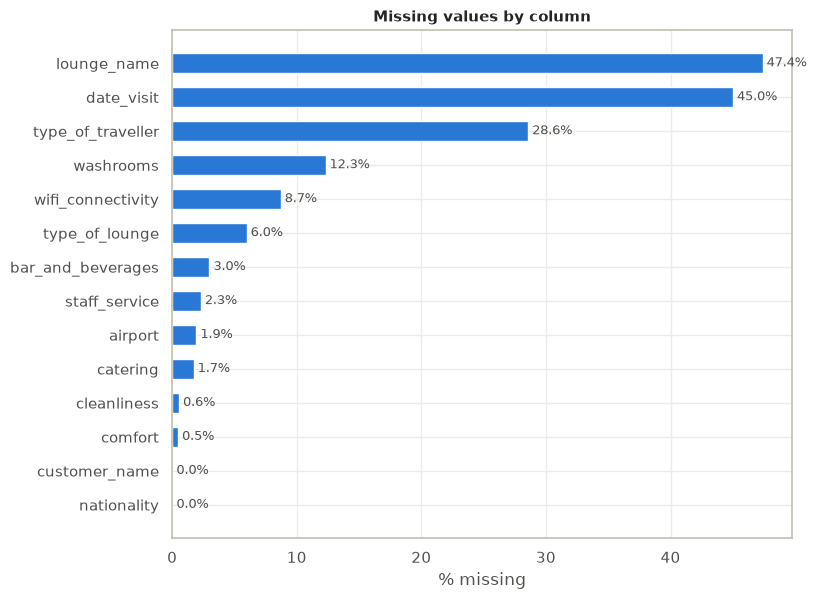

In [20]:
if len(missing):
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(missing) + 1))
    ax.barh(missing.index, missing["pct_missing"], color=MAIN, height=0.6)
    ax.invert_yaxis()
    ax.set_xlabel("% missing")
    ax.set_title("Missing values by column")
    for i, v in enumerate(missing["pct_missing"]):
        ax.text(v, i, f" {v:.1f}%", va="center", color="#52514e", fontsize=9)
    save_fig(fig, "missing_values")
    plt.show()

In [21]:
# Do nulls co-occur? (same rows missing several fields -> one upstream cause)
if len(missing) > 1:
    display(df[missing.index].isna().corr().round(2))

,lounge_name,date_visit,type_of_traveller,washrooms,wifi_connectivity,type_of_lounge,bar_and_beverages,staff_service,airport,catering,cleanliness,comfort,customer_name,nationality
lounge_name,1.00,0.31,-0.15,-0.06,-0.03,-0.08,-0.05,0.00,0.01,0.00,0.02,0.03,0.01,-0.01
date_visit,0.31,1.00,-0.10,-0.21,-0.10,0.23,-0.12,-0.07,0.13,-0.04,-0.03,-0.02,0.02,0.02
type_of_traveller,-0.15,-0.10,1.00,0.07,-0.01,0.40,0.04,0.04,0.01,0.02,-0.00,-0.02,0.02,0.02
washrooms,-0.06,-0.21,0.07,1.00,0.25,-0.03,0.20,0.19,-0.02,0.22,0.17,0.15,0.04,-0.01
wifi_connectivity,-0.03,-0.10,-0.01,0.25,1.00,-0.02,0.23,0.24,-0.01,0.31,0.21,0.20,-0.00,-0.00
type_of_lounge,-0.08,0.23,0.40,-0.03,-0.02,1.00,-0.02,0.00,0.07,-0.01,0.00,-0.01,-0.00,-0.00
bar_and_beverages,-0.05,-0.12,0.04,0.20,0.23,-0.02,1.00,0.28,-0.02,0.51,0.38,0.32,-0.00,-0.00
staff_service,0.00,-0.07,0.04,0.19,0.24,0.00,0.28,1.00,0.01,0.34,0.38,0.30,-0.00,-0.00
airport,0.01,0.13,0.01,-0.02,-0.01,0.07,-0.02,0.01,1.00,-0.01,-0.01,-0.01,-0.00,-0.00
catering,0.00,-0.04,0.02,0.22,0.31,-0.01,0.51,0.34,-0.01,1.00,0.52,0.45,-0.00,-0.00


In [22]:
# Rows with a missing TARGET cannot be used for supervised training
if TARGET and df[TARGET].isna().any():
    print(f"{df[TARGET].isna().sum()} rows have no {TARGET} -> drop before modelling")

## 4.2 Outliers<a id="sec-4-2"></a>

**Detect, don't delete.** Flag values outside `Q1 - 1.5·IQR` / `Q3 + 1.5·IQR`, then decide per column:
real but rare (keep, maybe log-transform) vs. error (fix in 3.5).

In [23]:
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ID_COLS and df[c].nunique() > 2]
if num_cols:
    outliers = outlier_report(df, num_cols)
    display(outliers[outliers.n_outliers > 0])
else:
    print("No numeric columns besides the id: nothing to check.")

,lower,upper,min,max,n_outliers,pct_outliers
column,,,,,,


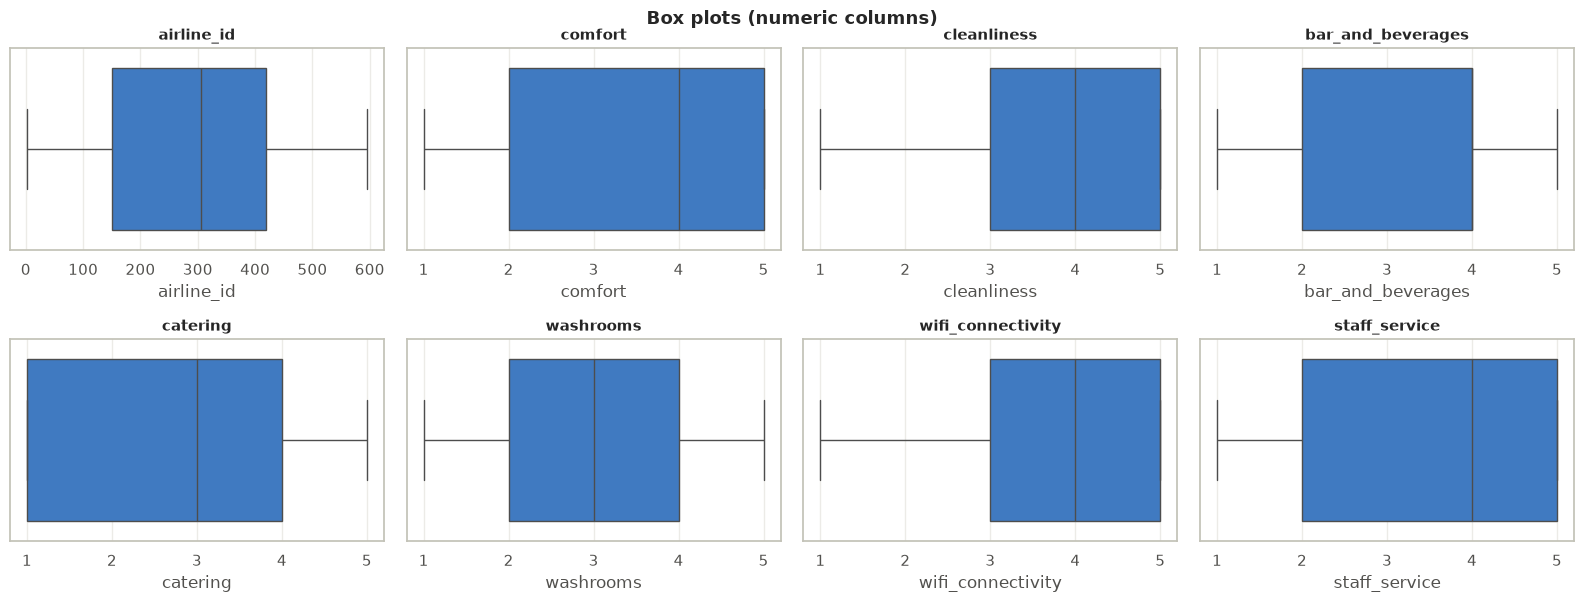

In [24]:
plot_grid(num_cols, lambda c, ax: sns.boxplot(x=df[c], ax=ax, color=MAIN, fliersize=3, linewidth=1),
          title="Box plots (numeric columns)", name="boxplots")

# 5. Attribute Combination<a id="sec-5"></a>

Create features that may explain the data better than the raw columns (ratios, rates, flags, date parts).
They go through the same EDA as everything else below.

how long after the trip the review was written, review length, how many ratings were filled in, review year.

In [25]:
# How long after the trip was the review written, how long is it, and how many ratings were filled in?
visit_col = next((c for c in ["date_flown", "date_visit"] if c in df.columns), None)
rating_cols = df.select_dtypes("float").columns.tolist()
if visit_col:
    df["days_to_review"] = (df["date_submitted"] - df[visit_col]).dt.days
df["review_length"] = df["review"].str.len()
df["n_ratings_filled"] = df[rating_cols].notna().sum(axis=1)
df["submitted_year"] = df["date_submitted"].dt.year


# 6. EDA<a id="sec-6"></a>

## 6.0 Classify Attributes<a id="sec-6-0"></a>

Every plot below is driven by these groups. Override with `CAT_COLS` in the config if a group looks wrong.

In [26]:
groups = classify_columns(df, TARGET, ID_COLS, CAT_COLS, CAT_MAX_UNIQUE)
for name, cols in groups.items():
    print(f"{name:<12} ({len(cols):>2}): {cols}")

const_attribs = groups["constant"]
bin_attribs = groups["binary"]
cat_attribs = groups["categorical"]
disc_attribs = groups["discrete"]
cont_attribs = groups["continuous"]
num_attribs = disc_attribs + cont_attribs

constant     ( 2): ['type_of_traveller', 'updated_at']
binary       ( 1): ['verify']
categorical  ( 9): ['airline_id', 'lounge_name', 'airport', 'type_of_lounge', 'date_submitted', 'date_visit', 'customer_name', 'nationality', 'review']
discrete     ( 8): ['comfort', 'cleanliness', 'bar_and_beverages', 'catering', 'washrooms', 'wifi_connectivity', 'staff_service', 'n_ratings_filled']
continuous   ( 3): ['days_to_review', 'review_length', 'submitted_year']


In [27]:
# Constant columns carry no information
if const_attribs:
    print("Dropping constant columns:", const_attribs)
    df = df.drop(columns=const_attribs)

# High-cardinality text columns (e.g. free text, raw model names) swamp plots
high_card = [c for c in cat_attribs if df[c].nunique() > 50]
print("High-cardinality categoricals (summarised, not plotted):", high_card)
cat_plot_attribs = [c for c in cat_attribs if c not in high_card]

Dropping constant columns: ['type_of_traveller', 'updated_at']
High-cardinality categoricals (summarised, not plotted): ['airline_id', 'lounge_name', 'airport', 'date_submitted', 'date_visit', 'customer_name', 'nationality', 'review']


## 6.1 Univariate<a id="sec-6-1"></a>

One column at a time: shape, spread, skew, rare levels.

### 6.1.1 Target

The target is `recommended`: the share of reviews that recommend (class balance). A rate far from 50% is normal here; it is the baseline every segment is compared with.

,count,pct
recommended,,
True,2651,52.13
False,2434,47.87


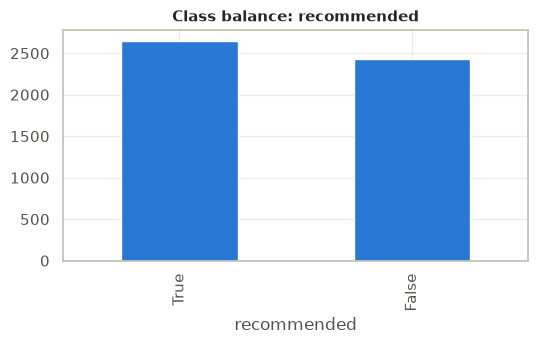

In [28]:
if TARGET and PROBLEM_TYPE == "regression":
    y = df[TARGET].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(y, kde=True, ax=axes[0], color=MAIN)
    axes[0].set_title(f"{TARGET} (skew = {y.skew():.2f})")
    sns.histplot(np.log1p(y), kde=True, ax=axes[1], color=MAIN)
    axes[1].set_title(f"log1p({TARGET}) (skew = {np.log1p(y).skew():.2f})")
    fig.tight_layout()
    save_fig(fig, "target_distribution")
    plt.show()
    display(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())
elif TARGET:
    counts = df[TARGET].value_counts()
    display(pd.DataFrame({"count": counts, "pct": counts / counts.sum() * 100}))
    fig, ax = plt.subplots(figsize=(6, 3))
    counts.plot.bar(ax=ax, color=MAIN)
    ax.set_title(f"Class balance: {TARGET}")
    save_fig(fig, "target_distribution")
    plt.show()

### 6.1.2 Numeric

In [29]:
skew = df[num_attribs].skew().sort_values(key=abs, ascending=False).to_frame("skew")
skew["shape"] = pd.cut(skew["skew"].abs(), [-np.inf, 0.5, 1, np.inf], labels=["symmetric", "moderate", "highly skewed"])
skew

,skew,shape
n_ratings_filled,-4.51,highly skewed
days_to_review,3.86,highly skewed
review_length,2.29,highly skewed
cleanliness,-0.75,moderate
wifi_connectivity,-0.74,moderate
comfort,-0.43,symmetric
staff_service,-0.40,symmetric
washrooms,-0.34,symmetric
submitted_year,0.34,symmetric
bar_and_beverages,-0.33,symmetric


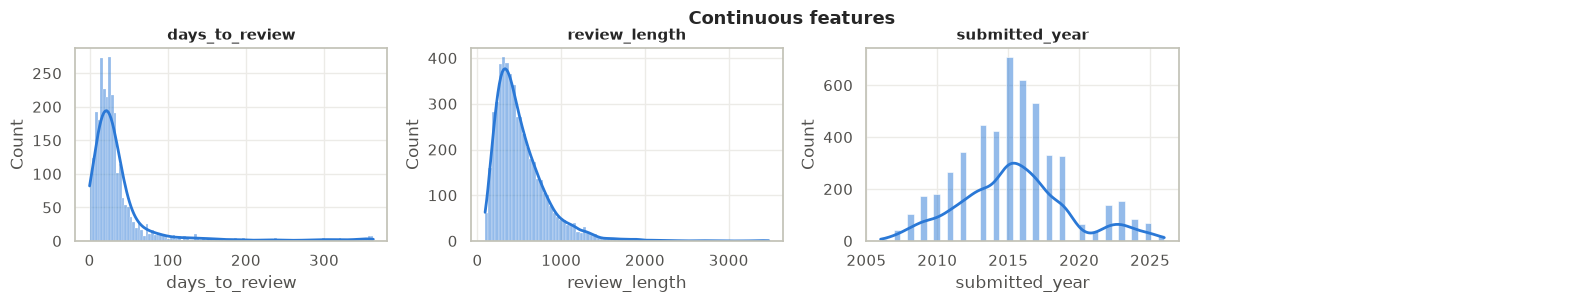

In [30]:
plot_grid(cont_attribs, lambda c, ax: sns.histplot(df[c], kde=True, ax=ax, color=MAIN),
          title="Continuous features", name="hist_continuous")

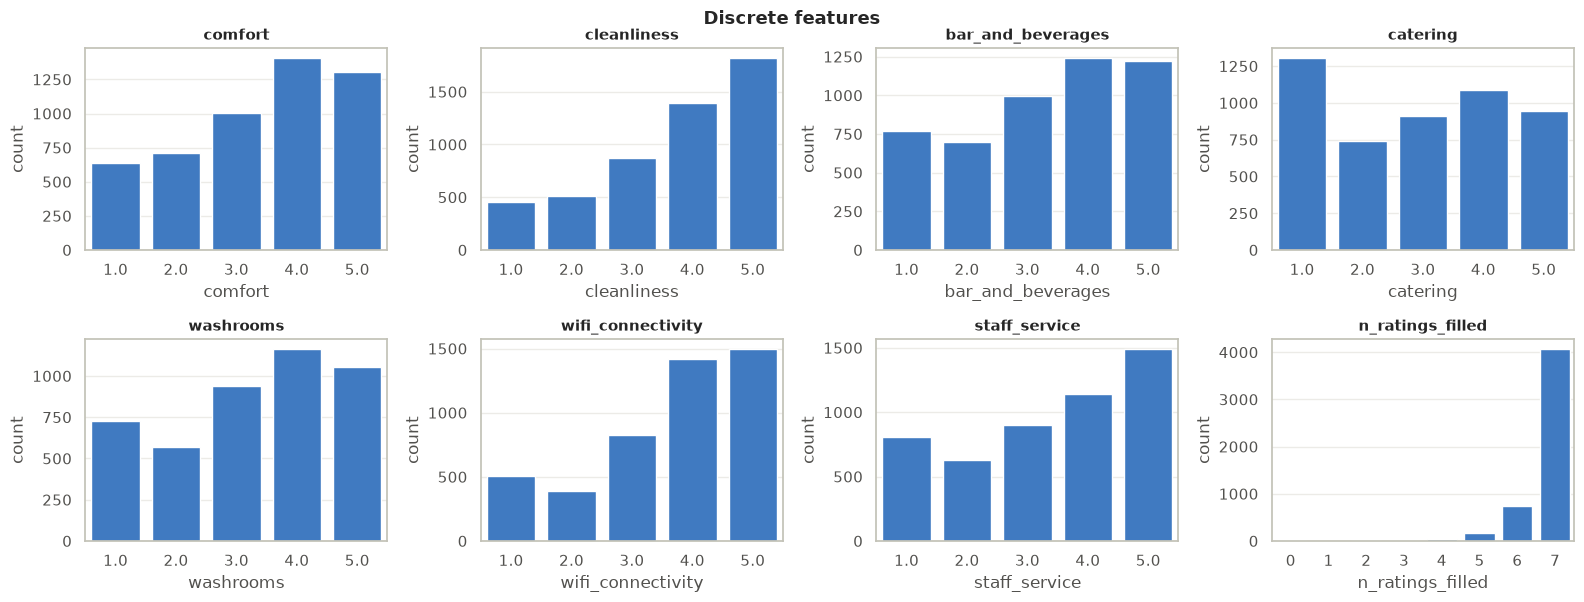

In [31]:
plot_grid(disc_attribs, lambda c, ax: sns.countplot(x=df[c], ax=ax, color=MAIN),
          title="Discrete features", name="count_discrete")

### 6.1.3 Binary

In [32]:
if bin_attribs:
    binary_share = (df[bin_attribs]
                    .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
                    .sort_values(ascending=False)
                    .to_frame("pct_majority_value"))
    binary_share["near_constant"] = binary_share["pct_majority_value"] > 95
    display(binary_share)
else:
    print("No binary columns.")

,pct_majority_value,near_constant
verify,78.37,False


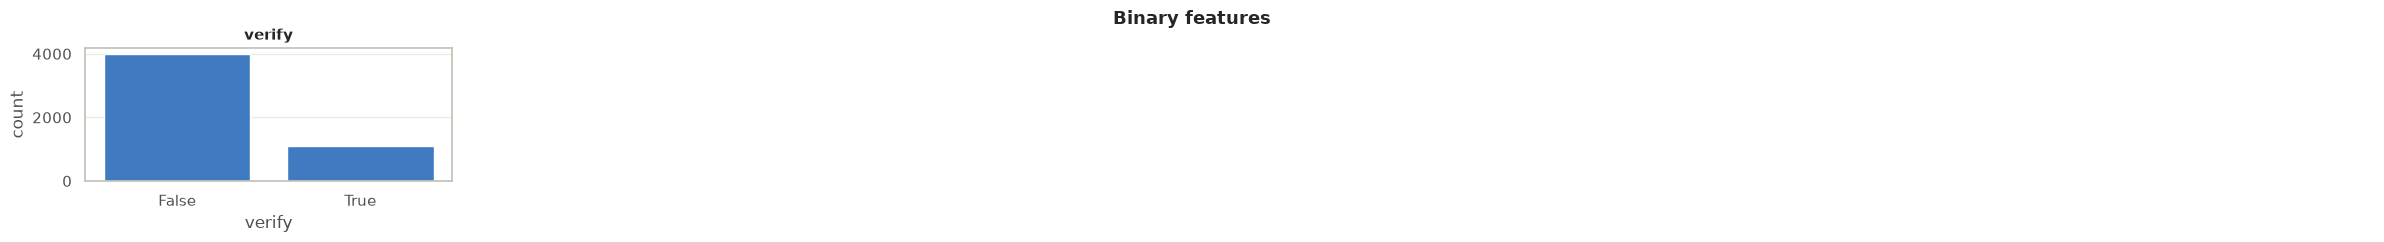

In [33]:
plot_grid(bin_attribs, lambda c, ax: sns.countplot(x=df[c], ax=ax, color=MAIN),
          ncols=6, height=2.4, title="Binary features", name="count_binary")

### 6.1.4 Categorical

In [34]:
for col in high_card:
    print(f"{col}: {df[col].nunique()} levels; top 5:")
    display(df[col].value_counts().head(5).to_frame())

airline_id: 159 levels; top 5:


,count
airline_id,
151,423
414,254
419,235
547,231
212,218


lounge_name: 1089 levels; top 5:


,count
lounge_name,
Admirals Club,89
Maple Leaf,67
United Club,61
Senator Lounge,54
Galleries Lounge,53


airport: 320 levels; top 5:


,count
airport,
London Heathrow Airport,410
Istanbul Airport,234
Bangkok Suvarnabhumi Airport,193
Hong Kong Airport,161
Singapore Changi Airport,147


... (6 outputs left out)

nationality: 98 levels; top 5:


,count
nationality,
United Kingdom,1566
United States,706
Australia,699
Canada,212
Germany,193


review: 4846 levels; top 5:


,count
review,
"I had a 6-hour layover at Paris CDG. Being a Priority Pass holder, I decided to use the ICare Lounge at T1. My departing Air France flight was from T2E so I had to make a trip to T1. ICare Lounge at CDG T1 is an embarrassment to a major air hub and airport like CDG. It is small, tired and dated. Passengers departing from T2 have to make a convoluted journey to T1 in order to access this lounge. Firstly, they have to take the shuttle train, CDGVAL to T1 having to pass through long passageways along the way. At T1, passengers have to go to the Alyzia counter to obtain a lounge invitation. Then one has to clear immigration before taking the elevator up to the lounge. The whole journey from T2 to ICare Lounge took 45 minutes including immigration clearance. If you are departing from T2 and have the Prioroty Pass to use the ICare Lounge, you'll be better off staying in T2 where there is adequate seating, shops and restaurants to keep you occupied.",3
"As an EVA Air Business Class passenger I spent some time at the Aspire Lounge 41 before my flight to Bangkok. The staff were friendly and professional and kept the place very clean. The lounge is very light with large windows overlooking the tarmac. There's a variety of seats including lounge chairs. The food and beverages are ok, but nothing special. I'd like to see some more options in snacks and non-alcoholic beverages like for example a variety of juices. There is a pay for shower available but I didn't use it. WiFi connection was easy and good. Overall it was a comfortable experience, a little improvement on the catering would give it that extra touch.",2
"Dreadful, dated, filthy lounge. Poor, uncomfortable sagging seating. Areas under semi-permanent repair. Broken, stained table lamps. Bad food. Try to avoid passing through Shanghai Pudong airport if at all possible.",2
"My expectations for these Beijing Capital Airport and Shanghai Pu Dong China Eastern lounges were modest, but they turned out to be better than I expected. The view from the PEK lounge was over a relatively quiet tarmac, while the PVG lounge had lots of natural light, but no view whatsoever. The PEK lounge had beer and Great Wall red and white wine. The Shanghai lounge offered more beverage choices with some liquor, including Bailey's, but not including rum. The wait staff were more efficient than friendly. The PVG lounge offered a cooking station, but since there was no menu, and the cooks didn't speak English, I have no idea what was available. There were sandwiches.and salads in the cooler. If I had anticipated world-class facilities, I would have been dissapointed, but as it was, this was a satisfactory way to await my flights.",2
"China Eastern Lounge in Shanghai Pudong. The lounge is over capacity and cannot handle all the passengers from China Eastern, Delta, and others. The good is the food, and showers being available. Food is available fresh or what is cooked and already out. Drinks are available from coke/beer and juice/ and wine. Sadly, the coffee machine was out of order going to Shanghai, and on my return to Shanghai. I had to use Starbucks outside the lounge. Also the WiFi is available for free but the Chinese government restricts all the popular apps so it is not of much use. Till the new terminal is completed and China Eastern shifts over to the new terminal and bigger lounge the overcrowding will remain an issue.",2


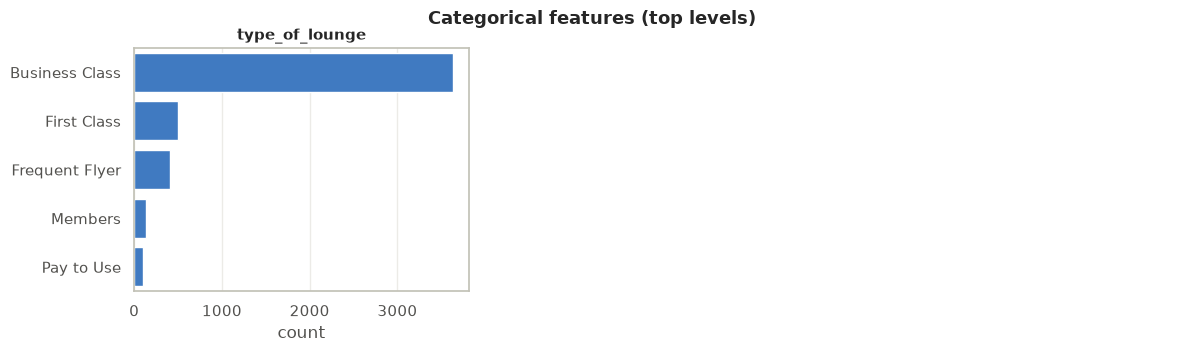

In [35]:
def plot_top_categories(col, ax):
    counts = df[col].value_counts()
    top = counts.head(TOP_N_CATEGORIES)
    sns.barplot(x=top.values, y=top.index.astype(str), ax=ax, color=MAIN, orient="h")
    ax.set_xlabel("count")
    ax.set_ylabel("")

plot_grid(cat_plot_attribs, plot_top_categories, ncols=3, height=3.5,
          title="Categorical features (top levels)", name="count_categorical")

In [36]:
# Rare levels (< 1% of rows) - candidates for grouping into "other"
rare = {c: df[c].value_counts(normalize=True).loc[lambda s: s < 0.01].index.tolist() for c in cat_plot_attribs}
{c: v for c, v in rare.items() if v}

{}

## 6.2 Bivariate<a id="sec-6-2"></a>

Each feature against **`recommended`**. This is where the candidate drivers come from. The charts show, for each rating value, the share of reviews that recommend; the last cell ranks the ratings by how strongly they move with `recommended`.

In [37]:
if TARGET and PROBLEM_TYPE == "regression":
    target_corr = (df[num_attribs + bin_attribs + [TARGET]]
                   .corr(method="spearman")[TARGET]
                   .drop(TARGET)
                   .sort_values(key=abs, ascending=False))
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(target_corr) + 1))
    colors = np.where(target_corr > 0, PALETTE[7], PALETTE[0])
    ax.barh(target_corr.index, target_corr.values, color=colors, height=0.7)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel(f"Spearman correlation with {TARGET}")
    ax.set_title(f"Features ranked by correlation with {TARGET}")
    save_fig(fig, "target_correlation")
    plt.show()

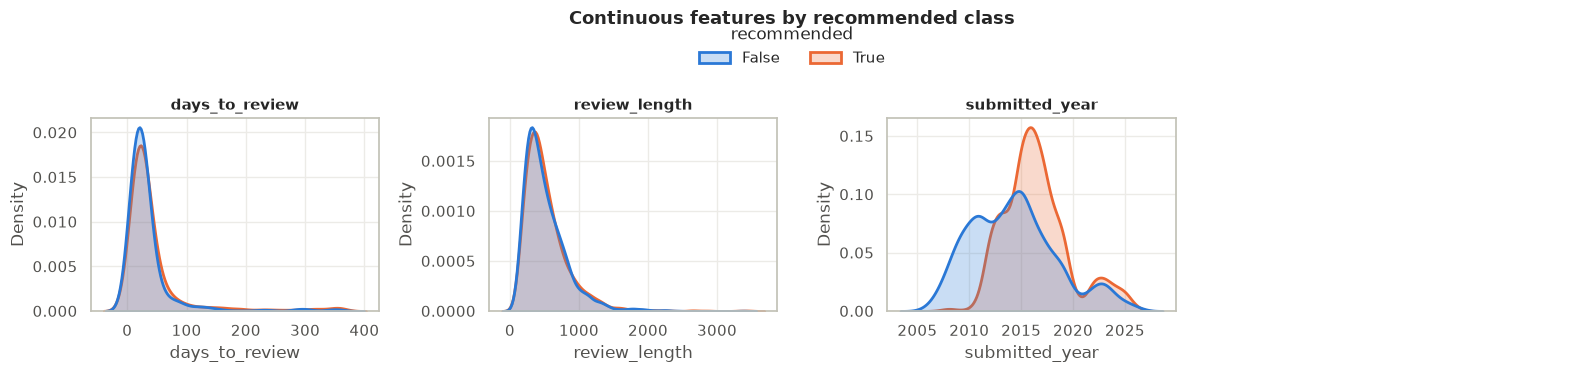

In [38]:
if TARGET and PROBLEM_TYPE == "regression":
    top_num = [c for c in target_corr.index if c in cont_attribs][:8]
    plot_grid(top_num,
              lambda c, ax: sns.regplot(data=df, x=c, y=TARGET, ax=ax, lowess=True,
                                        scatter_kws={"s": 8, "alpha": 0.35, "color": MAIN},
                                        line_kws={"color": PALETTE[1]}),
              title=f"Top continuous features vs {TARGET} (LOWESS trend)", name="scatter_vs_target")
elif TARGET:
    plot_grid(cont_attribs,
              lambda c, ax: sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True,
                                        alpha=0.25, linewidth=2, ax=ax),
              title=f"Continuous features by {TARGET} class", name="dist_by_target", shared_legend=True)

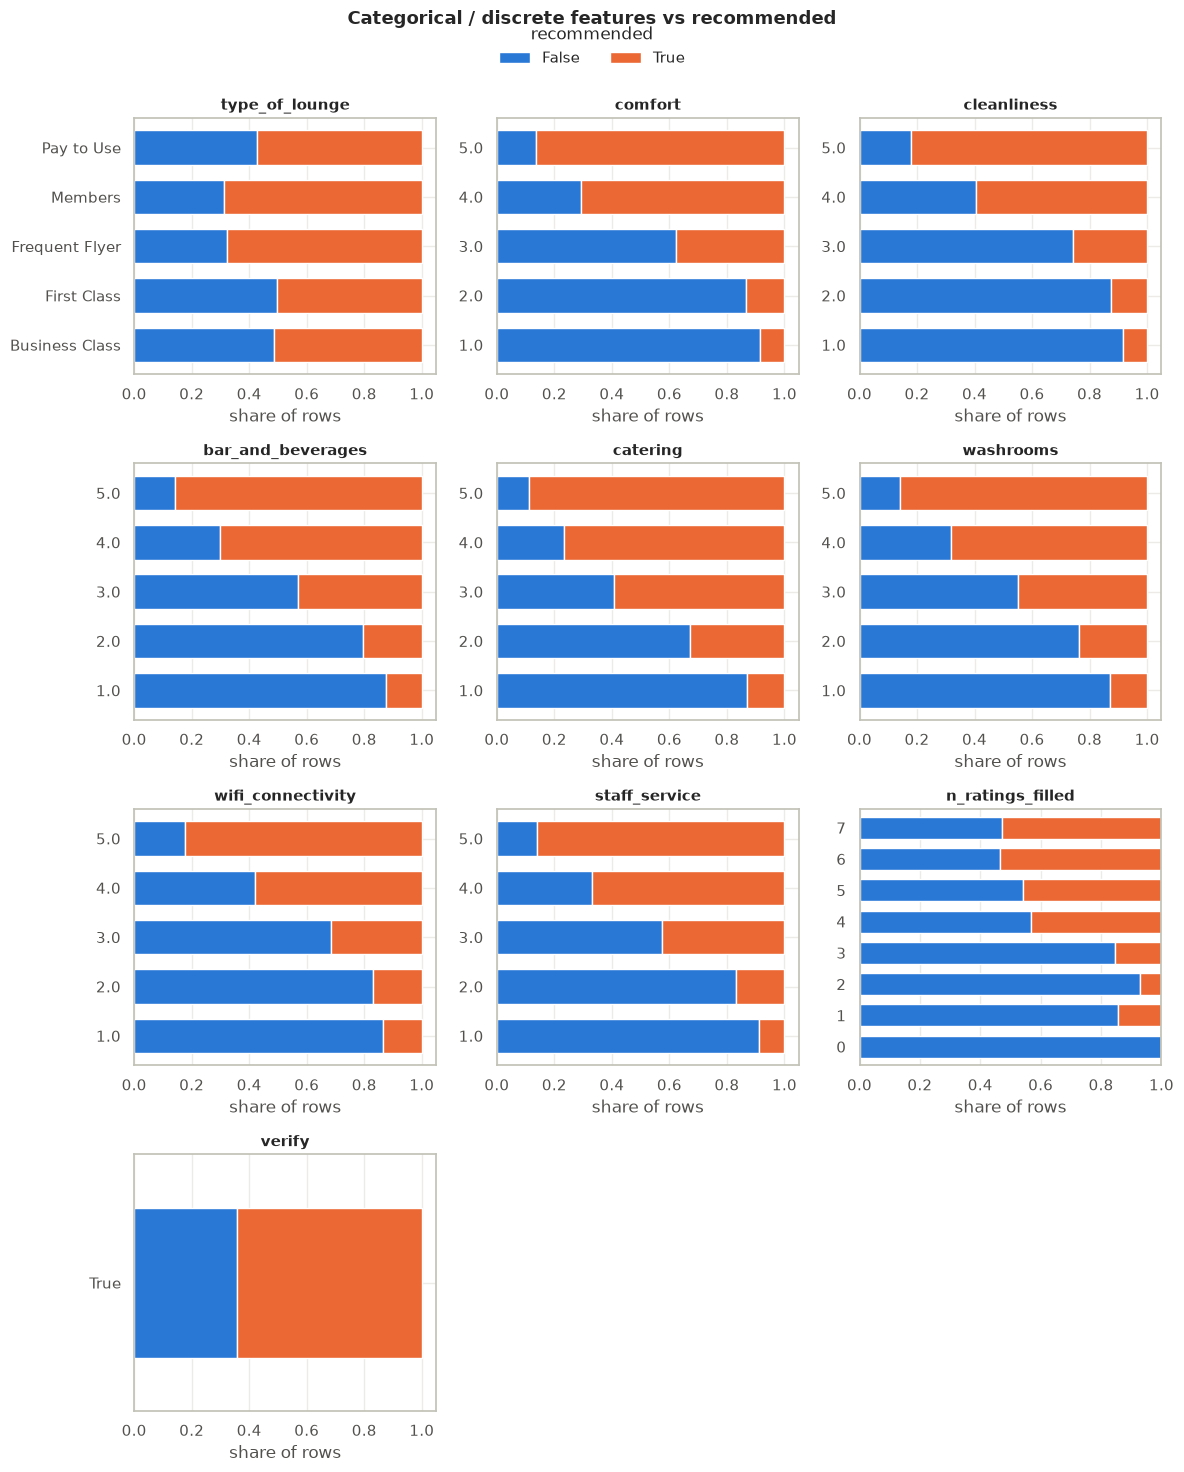

In [39]:
def plot_cat_vs_target(col, ax):
    order = df[col].value_counts().head(TOP_N_CATEGORIES).index
    if pd.api.types.is_numeric_dtype(df[col]):
        order = order.sort_values()
    if PROBLEM_TYPE == "regression":
        sns.boxplot(data=df[df[col].isin(order)], x=TARGET, y=col, order=order,
                    ax=ax, color=MAIN, fliersize=2, linewidth=1, orient="h")
    else:
        rate = pd.crosstab(df[col], df[TARGET], normalize="index").loc[order]
        rate.plot.barh(stacked=True, ax=ax, width=0.7, edgecolor="white", linewidth=1)
        ax.set_xlabel("share of rows")
    ax.set_ylabel("")

if TARGET:
    by_level = cat_plot_attribs + disc_attribs + (bin_attribs if PROBLEM_TYPE == "classification" else [])
    plot_grid(by_level, plot_cat_vs_target, ncols=3, height=3.5,
              title=f"Categorical / discrete features vs {TARGET}", name="cat_vs_target", shared_legend=True)

In [40]:
# Binary flags: difference in median target between the two groups (a = lower value, b = higher)
if TARGET and PROBLEM_TYPE == "regression":
    rows = {}
    for col in bin_attribs:
        a, b = sorted(df[col].dropna().unique())
        y_a, y_b = df.loc[df[col] == a, TARGET].dropna(), df.loc[df[col] == b, TARGET].dropna()
        rows[col] = {"a": a, "b": b, "median_when_a": y_a.median(), "median_when_b": y_b.median(),
                     "share_of_b": (df[col] == b).mean(), "p_value": stats.mannwhitneyu(y_a, y_b).pvalue}
    lift = pd.DataFrame(rows).T
    lift["diff"] = (lift["median_when_b"] - lift["median_when_a"]).astype(float)
    display(lift.sort_values("diff", key=abs, ascending=False))

In [41]:
# Which rating moves most with `recommended`? Spearman correlation of each rating with recommended (0/1).
# "Goes with", not "causes": this is observed data.
rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
recommended_01 = df[TARGET].astype("float")
driver_rank = (df[rating_cols].apply(lambda s: s.corr(recommended_01, method="spearman"))
               .sort_values(ascending=False).to_frame("spearman_with_recommended"))
driver_rank["n_rated"] = df[rating_cols].notna().sum()
display(driver_rank.round(2))

# Same ranking inside each of the 3 biggest segments (type_of_lounge): does the order change?
segment_col = "type_of_lounge"
top_segments = df[segment_col].value_counts().head(3).index
by_segment = pd.DataFrame({
    seg: df.loc[df[segment_col] == seg, rating_cols].apply(
        lambda s: s.corr(df.loc[df[segment_col] == seg, TARGET].astype("float"), method="spearman"))
    for seg in top_segments})
display(by_segment.round(2))


,spearman_with_recommended,n_rated
comfort,0.59,5061
staff_service,0.59,4968
catering,0.58,4997
cleanliness,0.55,5057
bar_and_beverages,0.55,4933
washrooms,0.53,4459
wifi_connectivity,0.51,4642


,Business Class,First Class,Frequent Flyer
comfort,0.59,0.54,0.63
cleanliness,0.56,0.53,0.59
bar_and_beverages,0.56,0.53,0.50
catering,0.58,0.54,0.58
washrooms,0.53,0.51,0.51
wifi_connectivity,0.50,0.47,0.48
staff_service,0.58,0.58,0.60


## 6.3 Multivariate<a id="sec-6-3"></a>

Features against **each other**: redundancy, leakage, interactions.

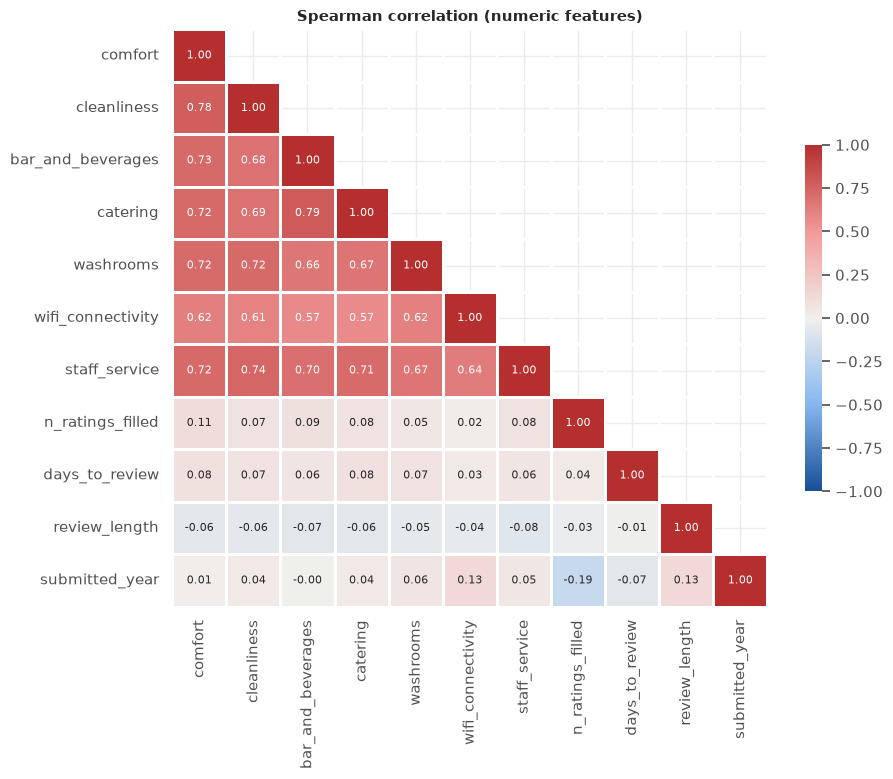

In [42]:
corr_cols = num_attribs
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(method="spearman")
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(0.6 * len(corr) + 3, 0.5 * len(corr) + 2))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
                linewidths=2, linecolor="white", annot_kws={"size": 8}, cbar_kws={"shrink": 0.6}, ax=ax)
    ax.set_title("Spearman correlation (numeric features)")
    save_fig(fig, "correlation_heatmap")
    plt.show()
else:
    print("Fewer than two numeric columns: no correlation to show.")

In [43]:
# Highly correlated pairs -> keep one of each pair (or combine) before modelling
if len(corr_cols) >= 2:
    pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack()
             .rename("r")
             .reset_index()
             .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
    display(pairs[pairs.r.abs() >= HIGH_CORR].sort_values("r", key=abs, ascending=False))

,feature_a,feature_b,r


In [44]:
# Leakage check: ID columns or row order should NOT predict the target
if TARGET and PROBLEM_TYPE == "regression":
    for col in ID_COLS:
        if col in df.columns:
            r = df[[col, TARGET]].corr(method="spearman").iloc[0, 1]
            print(f"corr({col}, {TARGET}) = {r:.2f}" + ("  <-- rows are ordered; shuffle before splitting" if abs(r) > 0.3 else ""))

### 6.3.1 Segments

Three views that answer the business questions: (1) the mean rating and recommend rate of each segment (`HUE`), (2) the trend by review year, (3) how many airlines or airports have enough reviews to be compared.
Hue splits use at most 3 groups; smaller groups fold into "other".

,n_reviews,recommend_rate
type_of_lounge,,
Business Class,3632,0.51
First Class,501,0.50
Frequent Flyer,412,0.68
other,236,0.64


type_of_lounge,Business Class,First Class,Frequent Flyer,other
comfort,3.37,3.58,3.52,3.45
cleanliness,3.69,3.94,3.80,3.69
bar_and_beverages,3.27,3.55,3.31,3.31
catering,2.89,3.22,2.87,3.08
washrooms,3.21,3.61,3.55,3.47
wifi_connectivity,3.61,3.71,3.89,3.95
staff_service,3.33,3.61,3.58,3.51


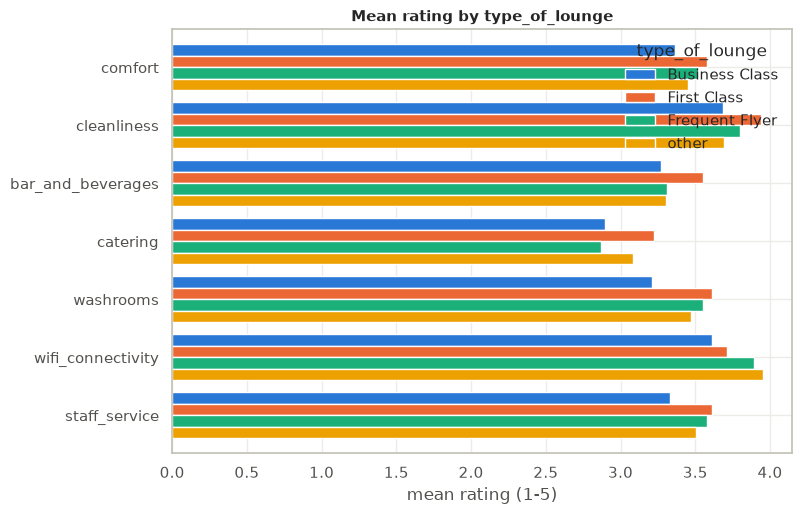

In [45]:
HUE = "type_of_lounge"   # the column that splits the rows into segments

if HUE in df.columns:
    # Keep the 3 biggest groups, fold the rest into "other"
    segmented = df[df[HUE].notna()]
    keep = segmented[HUE].value_counts().head(3).index
    segmented = segmented.assign(**{HUE: segmented[HUE].where(segmented[HUE].isin(keep), "other")})

    rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
    mean_rating = segmented.groupby(HUE)[rating_cols].mean().T      # rows = ratings, columns = segments
    segment_size = segmented[HUE].value_counts().to_frame("n_reviews")
    segment_size["recommend_rate"] = segmented[TARGET].astype("float").groupby(segmented[HUE]).mean()
    display(segment_size.round(2))
    display(mean_rating.round(2))

    fig, ax = plt.subplots(figsize=(8, 0.5 * len(rating_cols) + 2))
    mean_rating.plot.barh(ax=ax, width=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("mean rating (1-5)")
    ax.set_title(f"Mean rating by {HUE}")
    ax.legend(title=HUE, frameon=False)
    plt.show()


,n_reviews,recommend_rate,comfort,cleanliness,bar_and_beverages,catering,washrooms,wifi_connectivity,staff_service
submitted_year,,,,,,,,,
2006,8,0.00,3.75,4.00,3.25,3.50,3.38,3.38,3.12
2007,43,0.02,3.63,4.05,3.28,3.09,3.17,3.24,3.39
2008,103,0.07,3.49,3.78,3.38,2.99,3.17,3.38,3.32
2009,173,0.01,3.31,3.69,3.30,2.96,3.18,3.30,3.25
2010,180,0.02,3.52,3.82,3.44,3.03,3.32,3.49,3.38
2011,267,0.11,3.33,3.61,3.29,2.68,3.11,3.38,3.13
2012,342,0.58,3.62,3.86,3.43,3.01,3.47,3.64,3.57
2013,448,0.53,3.42,3.76,3.41,2.92,3.28,3.76,3.47
2014,424,0.47,3.19,3.52,3.06,2.68,3.01,3.41,3.08


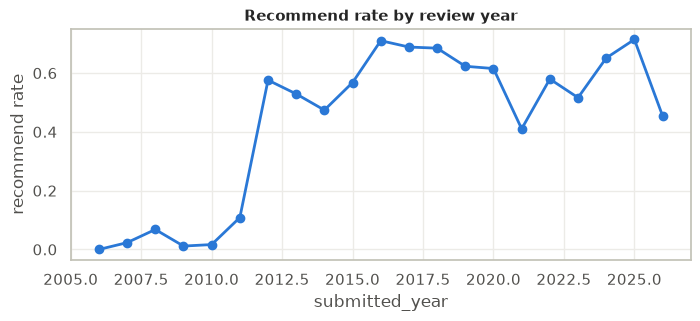

In [46]:
# Trend by review year: number of reviews, recommend rate and mean rating of each aspect
rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
yearly = df.groupby("submitted_year").agg(n_reviews=("review_id", "size"))
yearly["recommend_rate"] = df[TARGET].astype("float").groupby(df["submitted_year"]).mean()
display(yearly.round(2).join(df.groupby("submitted_year")[rating_cols].mean().round(2)))

fig, ax = plt.subplots(figsize=(8, 3))
yearly["recommend_rate"].plot(ax=ax, marker="o", color=MAIN)
ax.set_ylabel("recommend rate")
ax.set_title("Recommend rate by review year")
plt.show()


In [47]:
# Peer rule: only compare a airline that has at least 100 reviews
reviews_per_airline = df["airline_id"].value_counts()
enough = reviews_per_airline >= 100
print(f"{enough.sum()} of {len(enough)} airlines have at least 100 reviews")
print(f"They hold {reviews_per_airline[enough].sum() / len(df):.0%} of all reviews")


16 of 159 airlines have at least 100 reviews
They hold 57% of all reviews


In [48]:
# Pairplot of the strongest features (slow on wide data - keep it small)
if TARGET and PROBLEM_TYPE == "regression":
    pp_cols = [c for c in target_corr.index if c in cont_attribs][:4] + [TARGET]
    g = sns.pairplot(df[pp_cols].dropna(), corner=True, plot_kws={"s": 8, "alpha": 0.35, "color": MAIN},
                     diag_kws={"color": MAIN})
    g.figure.suptitle("Pairplot: strongest continuous features", y=1.02)
    save_fig(g.figure, "pairplot")
    plt.show()

# 7. Summary of Findings<a id="sec-7"></a>

The deliverable: one answer per question from 1.2, then the actions before staging. Drafted from the data, to be reviewed.
*Numbers come from running this notebook on the CSV. Counts printed from 3.5 onward are taken after the duplicates dropped in 3.4, so they can be slightly lower than counts on the raw file.*

**Answers to the questions in 1.2**
| # | Answer |
|---|---|
| D1 | Usable after cleaning: `lounge_name` is the main problem (47.4% missing, several spellings). |
| Q1 | For business class guests (3,632 reviews) the lowest mean rating is `catering` (2.89), then `washrooms` (3.21), `bar_and_beverages` (3.27), `staff_service` (3.33) and `comfort` (3.37); `wifi_connectivity` (3.61) and `cleanliness` (3.69) are the best. First class guests rate every aspect higher (`catering` 3.22). |
| Q2 | All aspects go with `recommended` about equally (Spearman 0.51 to 0.59): `comfort` 0.59, `staff_service` 0.59, `catering` 0.58, `cleanliness` 0.55, `bar_and_beverages` 0.55, `washrooms` 0.53, `wifi_connectivity` 0.51. No single aspect dominates. |
| Q3 | 16 of 159 airlines have at least 100 lounge reviews, holding 57% of the reviews. |
| Q4 | No pair of ratings reaches 0.8 (closest: `bar_and_beverages`-`catering` 0.79). |

**Data quality**
* 5,087 rows x 21 columns; 2 rows are identical except `review_id` (5,085 after 3.4).
* `lounge_name` is missing in 2,410 rows; 19 end with `LOUNGE REVIEW`; 2 are a single character (`=`); 65 lounges are written in more than one spelling.
* `type_of_traveller` has one value only (`Business`), so it adds nothing.
* `customer_name` ends with a number in 4,893 rows; 477 rows share their review text with another row.
* `nationality` is clean (0 of 5,084 values do not look like a country).
* Real missing data (do not fill): `lounge_name` 47.4%, `date_visit` 45.0%, `type_of_traveller` 28.6%, `washrooms` 12.3%, `wifi_connectivity` 8.7%.

**Target**
* `recommended`: 52.1% of the reviews recommend. By lounge type: frequent flyer 68%, business class 51%, first class 50%.
* The rate is 0-11% for 2006-2011 and 41-71% from 2012: the flag was probably not recorded before 2012, so use 2012 onward for rates.

**Key drivers**
* Spearman with `recommended`: `comfort` 0.59, `staff_service` 0.59, `catering` 0.58, `cleanliness` 0.55, `bar_and_beverages` 0.55, `washrooms` 0.53, `wifi_connectivity` 0.51. The range is narrow, so the lowest-scoring aspect (`catering`) is the clearer candidate.

**Redundancy / leakage**
* No pair of ratings is at or above 0.8.

**Actions before staging**
| Action | Column(s) | Why |
|---|---|---|
| Upper case, drop ` REVIEW` ending, `=` to null, merge spelling variants | `lounge_name` | inconsistent format |
| Strip the trailing number | `customer_name` | not part of a real name |
| Keep only values found in the `countries` seed, null the rest | `nationality` | country column |
| Keep one row of identical duplicates | all columns except `review_id` | duplicate reviews |
| Drop | `updated_at`, `type_of_traveller` or keep with a note | one value |
| Use reviews from 2012 on for recommend-rate comparisons | `date_submitted` | flag not recorded before |
| Do not fill nulls | `lounge_name`, `date_visit`, ratings | real missing data |


# 8. Hand-off to Modelling<a id="sec-8"></a>

Next steps (the template's modelling checklist does not apply: there is no model):

1. **Write the staging model** `stg__lounge_reviews` with the cleaning actions from section 7.
2. **Add dbt tests** (`unique`, `not_null`, `relationships`, `accepted_values`) for every rule that can be tested.
3. **Run `dbt run` and `dbt test`**, then compare row counts and null counts with the numbers in this notebook.
4. **Build the star schema** (facts and dimensions) on top of the staging models.